# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло.

## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.1 Мої відповіді:
1. ...

---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [3]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Лютянський Дмитро Юрійович"  # TODO: впишіть своє ПІБ точно як у списку групи

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

Ваш датасет (#5): Wine Quality


---
## 2. Що потрібно зробити

Нижче — загальний план роботи, без коду: код і пояснення до кожного кроку дивіться в **демо-ноутбуці лекції 3-4**, номери розділів позначені в дужках. Ваша задача — повторити той самий підхід на своєму датасеті, а не скопіювати код один в один: у вашого датасету інші колонки, інші типи пропусків (чи їх взагалі нема), інші викиди (чи їх нема) — рішення на кожному кроці обґрунтовуйте під свої дані, а не тому, що "так було в демо".

### 2.1. Підготовка даних

1. Завантажте свій датасет (демо 1.1) і перетворіть на `pandas.DataFrame` (1.2).
2. Зробіть спліт **train / val / test** одразу, до будь-якого аналізу (1.3) — і поясніть своїми словами, чому саме в такому порядку (нагадування: data leakage).
3. Загальний огляд (`head`/`info`/`describe`, 1.4).
4. Обробка пропусків (1.5) — **якщо вони є**. Немає пропусків — так і напишіть, це теж валідний результат, не треба їх штучно вигадувати.
5. EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?
6. Обробка викидів (1.7) — **за потреби**, з обґрунтуванням: звідки взявся викид і чому саме таке рішення (видалити / трансформувати / залишити).
7. Інженерія ознак (1.8) — **за потреби**: чи є сенс комбінувати/прибирати ознаки з високою кореляцією між собою.

### 2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування `nn.Linear` (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

Це ваш **варіант #1**, точка відліку для всього, що далі.

### 2.3. Нейромережа: щонайменше 2 різні архітектури

За зразком розділу 3 демо: `nn.Sequential` з прихованими шарами, ReLU, оптимізатор Adam.

Спробуйте **мінімум 2 архітектури**, які відрізняються не косметично — напр. різна кількість шарів, різна ширина шарів, чи інша функція активації (3.2). Кожна — окремий варіант.

### 2.4. Підбір гіперпараметрів: щонайменше 3 зміни

Візьміть архітектуру, яка показала себе краще, і поекспериментуйте з гіперпараметрами: learning rate, оптимізатор (SGD/Adam), кількість епох, розмір batch (якщо вирішите його ввести) тощо. Змінюйте **по одному параметру за раз** — інакше не зрозумієте, що саме вплинуло на результат.

**Разом (2.2 + 2.3 + 2.4):** щонайменше 5 варіантів моделі (1 лінійна + 2 архітектури + 2 гіперпараметри), до **10 варіантів** — якщо є час і бажання поекспериментувати більше, це тільки заохочується.

### 2.5. Логування і порівняння

Кожен варіант (2.2-2.4) логуйте в TensorBoard в окрему підпапку `RUNS_DIR` (як у 2.3/3.5 демо) — з осмисленою назвою (`linear`, `nn_v1_2layers`, `nn_v2_deeper`, `nn_v2_lr_0.001`, ...), щоб потім усі криві можна було накласти одна на одну (3.8 демо) і візуально порівняти.

Наприкінці зведіть усі варіанти в одну таблицю (модель → MSE/RMSE/MAE/R² на test) і дайте коротку письмову відповідь:
- Яка модель перемогла і наскільки суттєво?
- Чи виправдала себе нейромережа порівняно з лінійною регресією на вашому датасеті?
- Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

In [4]:
%pip install -q datasets

In [5]:
import pandas as pd
from datasets import load_dataset


In [6]:
wine_dataset = load_dataset(
    "codesignal/wine-quality",
    split="red"
)


README.md:   0%|          | 0.00/913 [00:00<?, ?B/s]

data/red-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 30.9kB            

data/red-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/white-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 73.3kB            

data/white-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating red split:   0%|          | 0/1599 [00:00<?, ? examples/s]

Generating white split:   0%|          | 0/4898 [00:00<?, ? examples/s]

In [7]:
df = wine_dataset.to_pandas()

In [8]:
print(df.shape)
display(df.head())
df.info()


(1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [9]:
print(df.columns.tolist())


['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


In [10]:
TARGET = "quality"

X = df.drop(columns=TARGET)
y = df[TARGET]


In [11]:
print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())
display(y.head())

X shape: (1599, 11)
y shape: (1599,)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


,quality
0,5
1,5
2,5
3,6
4,5


In [12]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# 70% train, 30% тимчасова вибірка
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Від 30%: половина validation, половина test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (1119, 11) (1119,)
Validation: (240, 11) (240,)
Test: (240, 11) (240,)


Дані були розділені на train, validation і test до аналізу та обробки. Це запобігає data leakage: модель і preprocessing не повинні використовувати статистики або закономірності з test-вибірки. Train використовується для навчання, validation — для вибору архітектури та гіперпараметрів, test — тільки для фінальної оцінки.


In [13]:
train_df = X_train.copy()
train_df["quality"] = y_train

print("Розмір train:", train_df.shape)

display(train_df.head())

train_df.info()

display(train_df.describe())

Розмір train: (1119, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1292,5.9,0.395,0.13,2.4,0.056,14.0,28.0,0.99362,3.62,0.67,12.4,6
932,7.6,0.400,0.29,1.9,0.078,29.0,66.0,0.99710,3.45,0.59,9.5,6
510,12.4,0.420,0.49,4.6,0.073,19.0,43.0,0.99780,3.02,0.61,9.5,5
146,5.8,0.680,0.02,1.8,0.087,21.0,94.0,0.99440,3.54,0.52,10.0,5
928,8.6,0.470,0.27,2.3,0.055,14.0,28.0,0.99516,3.18,0.80,11.2,5


<class 'pandas.core.frame.DataFrame'>
Index: 1119 entries, 1292 to 346
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1119 non-null   float64
 1   volatile acidity      1119 non-null   float64
 2   citric acid           1119 non-null   float64
 3   residual sugar        1119 non-null   float64
 4   chlorides             1119 non-null   float64
 5   free sulfur dioxide   1119 non-null   float64
 6   total sulfur dioxide  1119 non-null   float64
 7   density               1119 non-null   float64
 8   pH                    1119 non-null   float64
 9   sulphates             1119 non-null   float64
 10  alcohol               1119 non-null   float64
 11  quality               1119 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 113.6 KB


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1119.000000,1119.000000,1119.000000,1119.000000,1119.000000,1119.000000,1119.000000,1119.000000,1119.000000,1119.000000,1119.000000,1119.000000
mean,8.339768,0.528713,0.274549,2.548481,0.088023,16.245308,47.512958,0.996758,3.308061,0.662592,10.429193,5.636282
std,1.706176,0.180070,0.194838,1.385346,0.048683,10.529769,33.174783,0.001861,0.150496,0.176253,1.072105,0.808589
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.390000,8.400000,3.000000
25%,7.200000,0.390000,0.100000,1.900000,0.070000,8.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,39.000000,0.996800,3.310000,0.620000,10.200000,6.000000
75%,9.300000,0.640000,0.430000,2.600000,0.091000,22.000000,64.000000,0.997820,3.400000,0.740000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.400000,0.611000,68.000000,289.000000,1.003690,3.900000,2.000000,14.900000,8.000000


,count
quality,
3,7
4,37
5,477
6,446
7,139
8,13


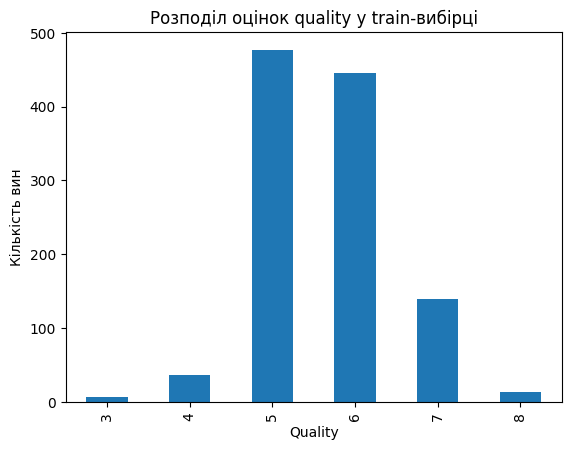

In [14]:
quality_counts = train_df["quality"].value_counts().sort_index()

display(quality_counts)

quality_counts.plot(
    kind="bar",
    title="Розподіл оцінок quality у train-вибірці",
    xlabel="Quality",
    ylabel="Кількість вин"
);

In [15]:
missing = train_df.isna().sum()
missing_percent = (missing / len(train_df) * 100).round(2)

missing_report = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": missing_percent
})

display(missing_report)

,missing_count,missing_percent
fixed acidity,0,0.0
volatile acidity,0,0.0
citric acid,0,0.0
residual sugar,0,0.0
chlorides,0,0.0
free sulfur dioxide,0,0.0
total sulfur dioxide,0,0.0
density,0,0.0
pH,0,0.0
sulphates,0,0.0


У train-вибірці пропусків не виявлено, тому імпутація не застосовувалася.


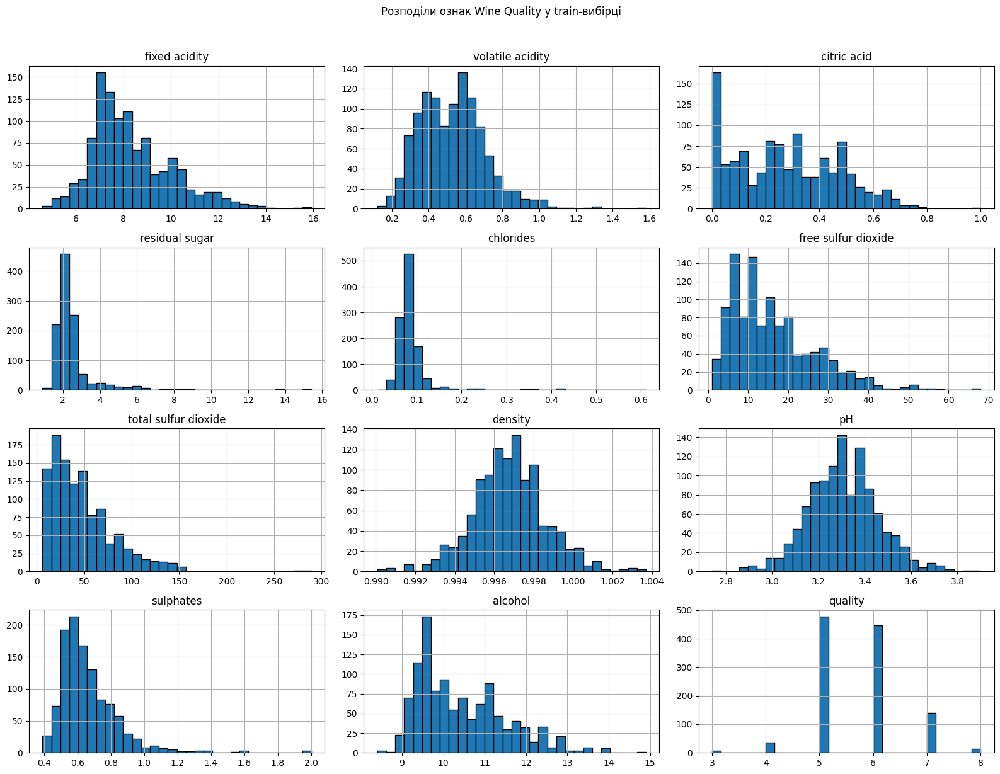

In [16]:
import matplotlib.pyplot as plt

train_df.hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Розподіли ознак Wine Quality у train-вибірці", y=1.02)
plt.tight_layout()
plt.show()

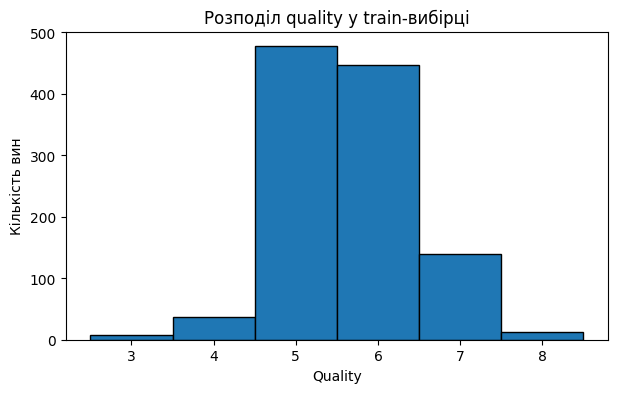

In [17]:
plt.figure(figsize=(7, 4))

plt.hist(
    y_train,
    bins=range(int(y_train.min()), int(y_train.max()) + 2),
    align="left",
    edgecolor="black"
)

plt.title("Розподіл quality у train-вибірці")
plt.xlabel("Quality")
plt.ylabel("Кількість вин")
plt.xticks(sorted(y_train.unique()))
plt.show()


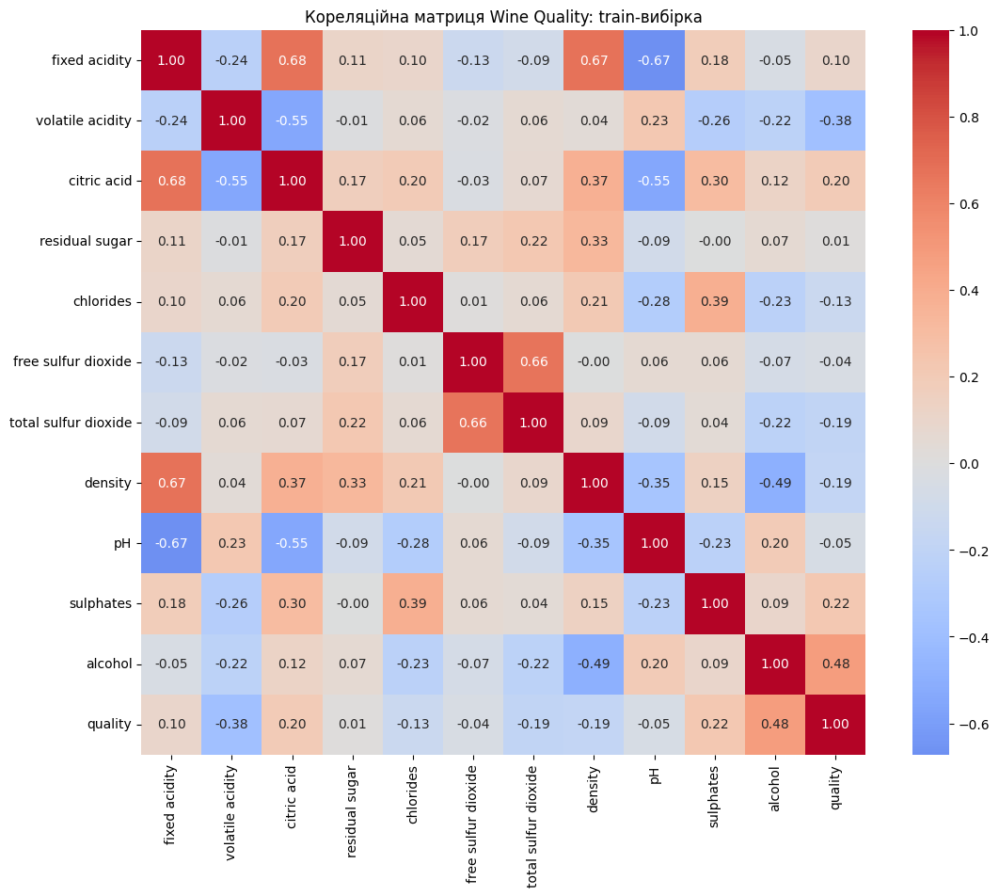

In [18]:
import seaborn as sns

correlation_matrix = train_df.corr(numeric_only=True)

plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Кореляційна матриця Wine Quality: train-вибірка")
plt.show()


In [19]:
quality_correlations = (
    correlation_matrix["quality"]
    .drop("quality")
    .sort_values()
)

display(quality_correlations)


,quality
volatile acidity,-0.379822
total sulfur dioxide,-0.194305
density,-0.187939
chlorides,-0.134891
pH,-0.048286
free sulfur dioxide,-0.044244
residual sugar,0.012602
fixed acidity,0.100873
citric acid,0.197186
sulphates,0.224026


In [20]:
feature_correlation = X_train.corr().abs()

pairs = (
    feature_correlation
    .where(
        __import__("numpy").triu(
            __import__("numpy").ones(feature_correlation.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .sort_values(ascending=False)
)

high_corr_pairs = pairs[pairs >= 0.80]

display(high_corr_pairs)

,,0


Пар ознак із абсолютною кореляцією 0.80 або більше не виявлено, тому ознаки не видалялися через мультиколінеарність.

In [21]:
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (X_train < lower_bound) | (X_train > upper_bound)

outlier_report = pd.DataFrame({
    "outlier_count": outlier_mask.sum(),
    "outlier_percent": (outlier_mask.mean() * 100).round(2),
    "lower_bound": lower_bound.round(3),
    "upper_bound": upper_bound.round(3)
}).sort_values("outlier_count", ascending=False)

display(outlier_report)

,outlier_count,outlier_percent,lower_bound,upper_bound
residual sugar,107,9.56,0.850,3.650
chlorides,66,5.90,0.039,0.122
sulphates,41,3.66,0.265,1.025
total sulfur dioxide,34,3.04,-41.000,127.000
fixed acidity,29,2.59,4.050,12.450
density,28,2.50,0.992,1.001
pH,23,2.06,2.925,3.685
free sulfur dioxide,19,1.70,-13.000,43.000
volatile acidity,14,1.25,0.015,1.015
alcohol,10,0.89,7.100,13.500


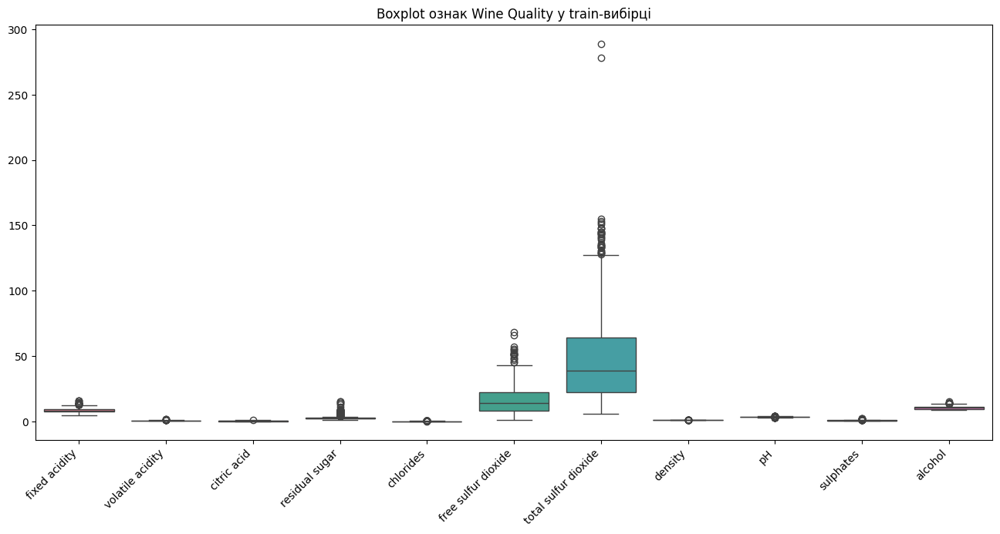

In [22]:
plt.figure(figsize=(16, 7))

sns.boxplot(data=X_train)

plt.title("Boxplot ознак Wine Quality у train-вибірці")
plt.xticks(rotation=45, ha="right")
plt.show()


За правилом IQR виявлено крайні значення в окремих хімічних показниках. Проте вони можуть бути реальними характеристиками вина, а не помилками вимірювання. Даних про помилки немає, тому викиди залишено. Стандартизація ознак допоможе моделі коректніше працювати з різними масштабами.

Додаткові ознаки не створювалися, оскільки вихідний набір уже містить 11 змістовних фізико-хімічних вимірювань. Мультиколінеарність буде оцінена за кореляційною матрицею. Якщо виявиться пара дуже сильно пов’язаних ознак, буде створено окремий варіант моделі без однієї з них, а рішення прийматиметься за validation-метриками, а не лише за кореляцією.


In [23]:
%pip install -q tensorboard

import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.tensorboard import SummaryWriter

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

RUNS_DIR = Path("runs")
RUN_NAME = "linear"
RUN_DIR = RUNS_DIR / RUN_NAME

RUN_DIR.mkdir(parents=True, exist_ok=True)

In [24]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [25]:
print("Середні значення train після scaling:")
print(np.round(X_train_scaled.mean(axis=0), 3))

print("\nСтандартні відхилення train після scaling:")
print(np.round(X_train_scaled.std(axis=0), 3))

Середні значення train після scaling:
[-0.  0.  0.  0.  0.  0. -0. -0. -0. -0.  0.]

Стандартні відхилення train після scaling:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [26]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train.to_numpy().reshape(-1, 1),
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val.to_numpy().reshape(-1, 1),
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test.to_numpy().reshape(-1, 1),
    dtype=torch.float32
)

print("X_train tensor:", X_train_tensor.shape)
print("y_train tensor:", y_train_tensor.shape)


X_train tensor: torch.Size([1119, 11])
y_train tensor: torch.Size([1119, 1])


In [27]:
n_features = X_train_tensor.shape[1]

linear_model = nn.Linear(
    in_features=n_features,
    out_features=1
)

print(linear_model)

Linear(in_features=11, out_features=1, bias=True)


In [28]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    linear_model.parameters(),
    lr=0.01
)

EPOCHS = 500

In [29]:
writer = SummaryWriter(log_dir=str(RUN_DIR))

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_model_state = None
best_epoch = 0

for epoch in range(1, EPOCHS + 1):
    # --- Навчання на train ---
    linear_model.train()

    train_predictions = linear_model(X_train_tensor)
    train_loss = criterion(train_predictions, y_train_tensor)

    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    # --- Оцінка на validation ---
    linear_model.eval()

    with torch.no_grad():
        val_predictions = linear_model(X_val_tensor)
        val_loss = criterion(val_predictions, y_val_tensor)

    train_loss_value = train_loss.item()
    val_loss_value = val_loss.item()

    train_losses.append(train_loss_value)
    val_losses.append(val_loss_value)

    # TensorBoard
    writer.add_scalar("Loss/train", train_loss_value, epoch)
    writer.add_scalar("Loss/validation", val_loss_value, epoch)

    # Зберігаємо ваги моделі з найкращим validation MSE
    if val_loss_value < best_val_loss:
        best_val_loss = val_loss_value
        best_model_state = copy.deepcopy(linear_model.state_dict())
        best_epoch = epoch

writer.close()

print(f"Найкраща validation MSE: {best_val_loss:.4f}")
print(f"Найкраща епоха: {best_epoch}")

Найкраща validation MSE: 3.4351
Найкраща епоха: 500


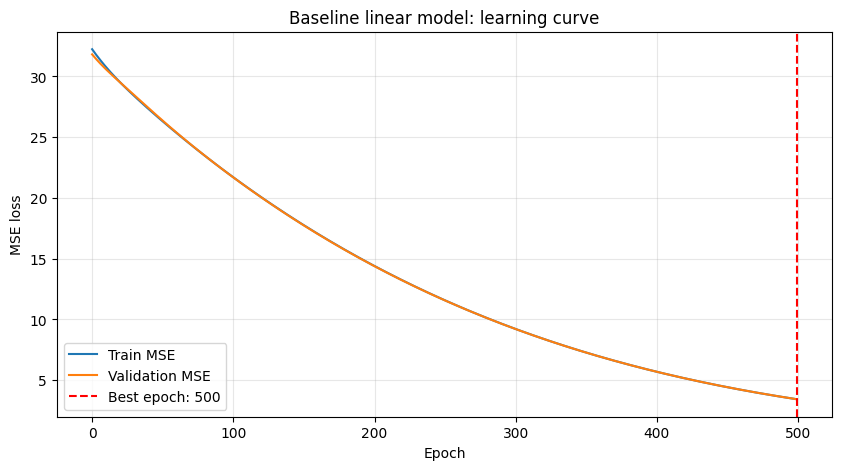

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Train MSE")
plt.plot(val_losses, label="Validation MSE")

plt.axvline(
    best_epoch - 1,
    color="red",
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.title("Baseline linear model: learning curve")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [31]:
linear_model.load_state_dict(best_model_state)
linear_model.eval()

with torch.no_grad():
    test_predictions_tensor = linear_model(X_test_tensor)

y_test_true = y_test_tensor.numpy().ravel()
y_test_pred = test_predictions_tensor.numpy().ravel()

linear_test_mse = mean_squared_error(y_test_true, y_test_pred)
linear_test_rmse = np.sqrt(linear_test_mse)
linear_test_mae = mean_absolute_error(y_test_true, y_test_pred)
linear_test_r2 = r2_score(y_test_true, y_test_pred)

linear_results = {
    "model": "linear",
    "test_mse": linear_test_mse,
    "test_rmse": linear_test_rmse,
    "test_mae": linear_test_mae,
    "test_r2": linear_test_r2,
    "best_epoch": best_epoch
}

pd.DataFrame([linear_results]).round(4)


,model,test_mse,test_rmse,test_mae,test_r2,best_epoch
0,linear,3.4174,1.8486,1.7446,-4.2491,500


In [32]:
weights = linear_model.weight.detach().numpy().ravel()
bias = linear_model.bias.detach().item()

weights_df = pd.DataFrame({
    "feature": X_train.columns,
    "weight": weights,
    "abs_weight": np.abs(weights)
}).sort_values("abs_weight", ascending=False)

print(f"Bias: {bias:.4f}")
display(weights_df.round(4))

Bias: 3.9063


,feature,weight,abs_weight
10,alcohol,0.3380,0.3380
1,volatile acidity,-0.2007,0.2007
9,sulphates,0.1240,0.1240
6,total sulfur dioxide,-0.1200,0.1200
8,pH,-0.1074,0.1074
4,chlorides,-0.0843,0.0843
5,free sulfur dioxide,0.0593,0.0593
2,citric acid,-0.0570,0.0570
7,density,0.0357,0.0357
0,fixed acidity,-0.0264,0.0264


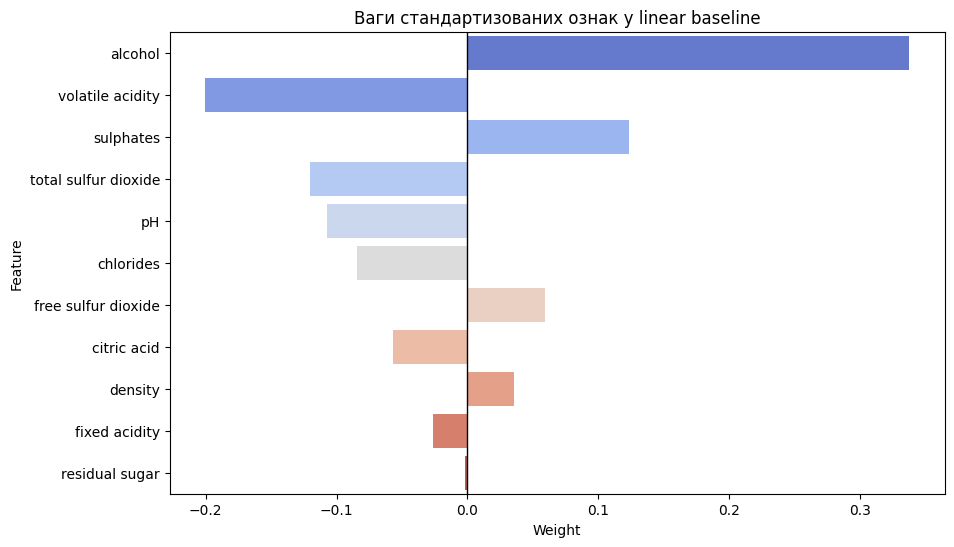

In [33]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=weights_df,
    x="weight",
    y="feature",
    hue="feature",
    legend=False,
    palette="coolwarm"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Ваги стандартизованих ознак у linear baseline")
plt.xlabel("Weight")
plt.ylabel("Feature")
plt.show()

Оскільки всі ознаки стандартизовані, вага показує, як змінюється прогнозована якість вина при збільшенні відповідної ознаки на одне стандартне відхилення train-вибірки за сталих інших ознак. Додатна вага означає вищий прогноз якості, від’ємна — нижчий. Великі за модулем ваги означають сильніший внесок у лінійний прогноз, але не доводять причинний вплив.

In [34]:
%load_ext tensorboard
%tensorboard --logdir runs

<IPython.core.display.Javascript object>

In [35]:
X_train_tensor, X_val_tensor
y_train_tensor, y_val_tensor
n_features
RUNS_DIR

PosixPath('runs')

In [36]:
def train_nn_model(
    model,
    run_name,
    epochs=500,
    learning_rate=0.001
):
    run_dir = RUNS_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    writer = SummaryWriter(log_dir=str(run_dir))

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_model_state = None
    best_epoch = 0

    for epoch in range(1, epochs + 1):
        # Train
        model.train()

        train_predictions = model(X_train_tensor)
        train_loss = criterion(train_predictions, y_train_tensor)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        # Validation
        model.eval()

        with torch.no_grad():
            val_predictions = model(X_val_tensor)
            val_loss = criterion(val_predictions, y_val_tensor)

        train_loss_value = train_loss.item()
        val_loss_value = val_loss.item()

        train_losses.append(train_loss_value)
        val_losses.append(val_loss_value)

        writer.add_scalar("Loss/train", train_loss_value, epoch)
        writer.add_scalar("Loss/validation", val_loss_value, epoch)

        if val_loss_value < best_val_loss:
            best_val_loss = val_loss_value
            best_model_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

    writer.close()

    model.load_state_dict(best_model_state)

    return {
        "model": model,
        "run_name": run_name,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "best_val_mse": best_val_loss,
        "best_epoch": best_epoch,
        "learning_rate": learning_rate,
        "epochs": epochs
    }

In [37]:
torch.manual_seed(RANDOM_STATE)

nn_v1_2layers = nn.Sequential(
    nn.Linear(n_features, 32),
    nn.ReLU(),

    nn.Linear(32, 16),
    nn.ReLU(),

    nn.Linear(16, 1)
)

print(nn_v1_2layers)


Sequential(
  (0): Linear(in_features=11, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
)


In [38]:
nn_v1_results = train_nn_model(
    model=nn_v1_2layers,
    run_name="nn_v1_2layers",
    epochs=500,
    learning_rate=0.001
)

print("Best validation MSE:", round(nn_v1_results["best_val_mse"], 4))
print("Best epoch:", nn_v1_results["best_epoch"])

Best validation MSE: 0.6993
Best epoch: 500


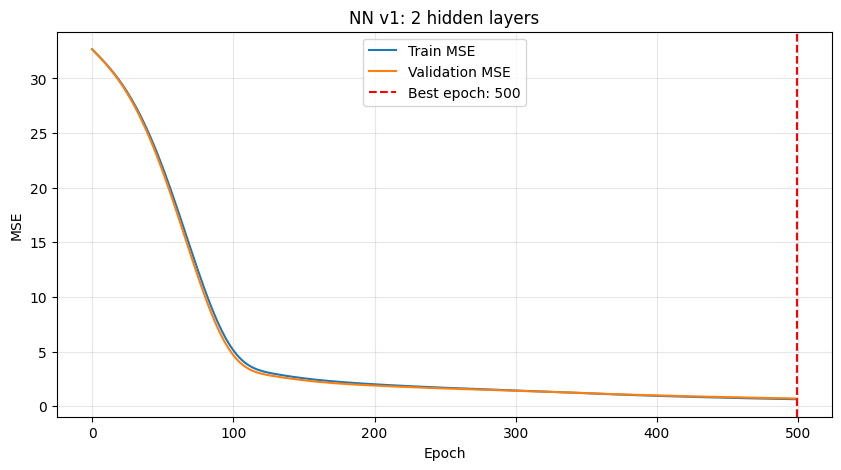

In [39]:
plt.figure(figsize=(10, 5))

plt.plot(nn_v1_results["train_losses"], label="Train MSE")
plt.plot(nn_v1_results["val_losses"], label="Validation MSE")

plt.axvline(
    nn_v1_results["best_epoch"] - 1,
    color="red",
    linestyle="--",
    label=f"Best epoch: {nn_v1_results['best_epoch']}"
)

plt.title("NN v1: 2 hidden layers")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [40]:
torch.manual_seed(RANDOM_STATE)

nn_v2_deeper = nn.Sequential(
    nn.Linear(n_features, 64),
    nn.ReLU(),

    nn.Linear(64, 32),
    nn.ReLU(),

    nn.Linear(32, 16),
    nn.ReLU(),

    nn.Linear(16, 1)
)

print(nn_v2_deeper)

Sequential(
  (0): Linear(in_features=11, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=16, bias=True)
  (5): ReLU()
  (6): Linear(in_features=16, out_features=1, bias=True)
)


In [41]:
nn_v2_results = train_nn_model(
    model=nn_v2_deeper,
    run_name="nn_v2_deeper",
    epochs=500,
    learning_rate=0.001
)

print("Best validation MSE:", round(nn_v2_results["best_val_mse"], 4))
print("Best epoch:", nn_v2_results["best_epoch"])


Best validation MSE: 0.4376
Best epoch: 500


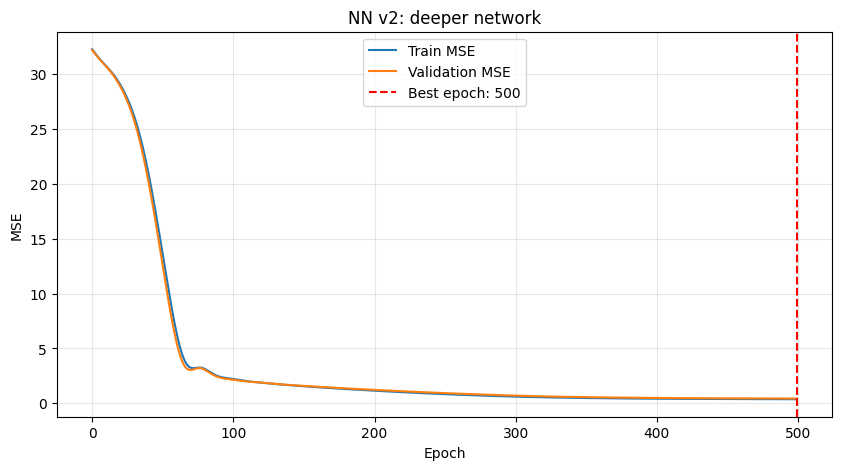

In [42]:
plt.figure(figsize=(10, 5))

plt.plot(nn_v2_results["train_losses"], label="Train MSE")
plt.plot(nn_v2_results["val_losses"], label="Validation MSE")

plt.axvline(
    nn_v2_results["best_epoch"] - 1,
    color="red",
    linestyle="--",
    label=f"Best epoch: {nn_v2_results['best_epoch']}"
)

plt.title("NN v2: deeper network")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [43]:
architecture_comparison = pd.DataFrame([
    {
        "model": "nn_v1_2layers",
        "architecture": "11 → 32 → 16 → 1",
        "best_validation_mse": nn_v1_results["best_val_mse"],
        "best_epoch": nn_v1_results["best_epoch"]
    },
    {
        "model": "nn_v2_deeper",
        "architecture": "11 → 64 → 32 → 16 → 1",
        "best_validation_mse": nn_v2_results["best_val_mse"],
        "best_epoch": nn_v2_results["best_epoch"]
    }
]).sort_values("best_validation_mse")

display(architecture_comparison.round(4))

,model,architecture,best_validation_mse,best_epoch
1,nn_v2_deeper,11 → 64 → 32 → 16 → 1,0.4376,500
0,nn_v1_2layers,11 → 32 → 16 → 1,0.6993,500


In [44]:
def train_nn_model(
    model,
    run_name,
    epochs=500,
    learning_rate=0.001,
    optimizer_name="Adam"
):
    run_dir = RUNS_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    writer = SummaryWriter(log_dir=str(run_dir))

    criterion = nn.MSELoss()

    if optimizer_name == "Adam":
        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=learning_rate
        )

    elif optimizer_name == "SGD":
        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=learning_rate
        )

    else:
        raise ValueError("optimizer_name має бути 'Adam' або 'SGD'")

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_model_state = None
    best_epoch = 0

    for epoch in range(1, epochs + 1):
        model.train()

        train_predictions = model(X_train_tensor)
        train_loss = criterion(train_predictions, y_train_tensor)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        model.eval()

        with torch.no_grad():
            val_predictions = model(X_val_tensor)
            val_loss = criterion(val_predictions, y_val_tensor)

        train_loss_value = train_loss.item()
        val_loss_value = val_loss.item()

        train_losses.append(train_loss_value)
        val_losses.append(val_loss_value)

        writer.add_scalar("Loss/train", train_loss_value, epoch)
        writer.add_scalar("Loss/validation", val_loss_value, epoch)

        if val_loss_value < best_val_loss:
            best_val_loss = val_loss_value
            best_model_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

    writer.close()

    model.load_state_dict(best_model_state)

    return {
        "model": model,
        "run_name": run_name,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "best_val_mse": best_val_loss,
        "best_epoch": best_epoch,
        "learning_rate": learning_rate,
        "epochs": epochs,
        "optimizer": optimizer_name
    }

In [45]:
def build_nn_v2():
    return nn.Sequential(
        nn.Linear(n_features, 64),
        nn.ReLU(),

        nn.Linear(64, 32),
        nn.ReLU(),

        nn.Linear(32, 16),
        nn.ReLU(),

        nn.Linear(16, 1)
    )

In [46]:
torch.manual_seed(RANDOM_STATE)

nn_v2_lr_0003 = build_nn_v2()

nn_v2_lr_0003_results = train_nn_model(
    model=nn_v2_lr_0003,
    run_name="nn_v2_lr_0.0003",
    epochs=500,
    learning_rate=0.0003,
    optimizer_name="Adam"
)

print("Best validation MSE:", round(nn_v2_lr_0003_results["best_val_mse"], 4))
print("Best epoch:", nn_v2_lr_0003_results["best_epoch"])


Best validation MSE: 1.2782
Best epoch: 500


In [48]:
torch.manual_seed(RANDOM_STATE)

nn_v2_sgd = build_nn_v2()

nn_v2_sgd_results = train_nn_model(
    model=nn_v2_sgd,
    run_name="nn_v2_sgd",
    epochs=500,
    learning_rate=0.001,
    optimizer_name="SGD"
)

print("Best validation MSE:", round(nn_v2_sgd_results["best_val_mse"], 4))
print("Best epoch:", nn_v2_sgd_results["best_epoch"])

Best validation MSE: 0.7472
Best epoch: 500


In [49]:
torch.manual_seed(RANDOM_STATE)

nn_v2_epochs_1000 = build_nn_v2()

nn_v2_epochs_1000_results = train_nn_model(
    model=nn_v2_epochs_1000,
    run_name="nn_v2_epochs_1000",
    epochs=1000,
    learning_rate=0.001,
    optimizer_name="Adam"
)

print("Best validation MSE:", round(nn_v2_epochs_1000_results["best_val_mse"], 4))
print("Best epoch:", nn_v2_epochs_1000_results["best_epoch"])

Best validation MSE: 0.4044
Best epoch: 923


In [50]:
hyperparameter_comparison = pd.DataFrame([
    {
        "model": "nn_v2_deeper_base",
        "changed_parameter": "нічого: baseline для NN",
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "epochs": 500,
        "best_validation_mse": nn_v2_results["best_val_mse"],
        "best_epoch": nn_v2_results["best_epoch"]
    },
    {
        "model": "nn_v2_lr_0.0003",
        "changed_parameter": "learning_rate: 0.001 → 0.0003",
        "optimizer": "Adam",
        "learning_rate": 0.0003,
        "epochs": 500,
        "best_validation_mse": nn_v2_lr_0003_results["best_val_mse"],
        "best_epoch": nn_v2_lr_0003_results["best_epoch"]
    },
    {
        "model": "nn_v2_sgd",
        "changed_parameter": "optimizer: Adam → SGD",
        "optimizer": "SGD",
        "learning_rate": 0.001,
        "epochs": 500,
        "best_validation_mse": nn_v2_sgd_results["best_val_mse"],
        "best_epoch": nn_v2_sgd_results["best_epoch"]
    },
    {
        "model": "nn_v2_epochs_1000",
        "changed_parameter": "epochs: 500 → 1000",
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "epochs": 1000,
        "best_validation_mse": nn_v2_epochs_1000_results["best_val_mse"],
        "best_epoch": nn_v2_epochs_1000_results["best_epoch"]
    }
]).sort_values("best_validation_mse")

display(hyperparameter_comparison.round(4))

,model,changed_parameter,optimizer,learning_rate,epochs,best_validation_mse,best_epoch
3,nn_v2_epochs_1000,epochs: 500 → 1000,Adam,0.0010,1000,0.4044,923
0,nn_v2_deeper_base,нічого: baseline для NN,Adam,0.0010,500,0.4376,500
2,nn_v2_sgd,optimizer: Adam → SGD,SGD,0.0010,500,0.7472,500
1,nn_v2_lr_0.0003,learning_rate: 0.001 → 0.0003,Adam,0.0003,500,1.2782,500


In [51]:
def calculate_test_metrics(model, model_name):
    model.eval()

    with torch.no_grad():
        predictions_tensor = model(X_test_tensor)

    y_true = y_test_tensor.numpy().ravel()
    y_pred = predictions_tensor.numpy().ravel()

    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "model": model_name,
        "test_mse": mse,
        "test_rmse": rmse,
        "test_mae": mae,
        "test_r2": r2
    }

In [52]:
all_test_results = [
    calculate_test_metrics(
        linear_model,
        "linear"
    ),

    calculate_test_metrics(
        nn_v1_results["model"],
        "nn_v1_2layers"
    ),

    calculate_test_metrics(
        nn_v2_results["model"],
        "nn_v2_deeper_base"
    ),

    calculate_test_metrics(
        nn_v2_lr_0003_results["model"],
        "nn_v2_lr_0.0003"
    ),

    calculate_test_metrics(
        nn_v2_sgd_results["model"],
        "nn_v2_sgd"
    ),

    calculate_test_metrics(
        nn_v2_epochs_1000_results["model"],
        "nn_v2_epochs_1000"
    )
]

final_results = (
    pd.DataFrame(all_test_results)
    .sort_values("test_rmse")
    .reset_index(drop=True)
)

display(final_results.round(4))


,model,test_mse,test_rmse,test_mae,test_r2
0,nn_v2_epochs_1000,0.4215,0.6492,0.4922,0.3526
1,nn_v2_deeper_base,0.4317,0.6570,0.5027,0.3369
2,nn_v1_2layers,0.5966,0.7724,0.6024,0.0836
3,nn_v2_sgd,0.6972,0.8350,0.6433,-0.0710
4,nn_v2_lr_0.0003,1.0791,1.0388,0.8092,-0.6575
5,linear,3.4174,1.8486,1.7446,-4.2491


Переможець: nn_v2_epochs_1000
Test RMSE переможця: 0.6492
Test R² переможця: 0.3526
Зміна RMSE відносно linear: 64.88%


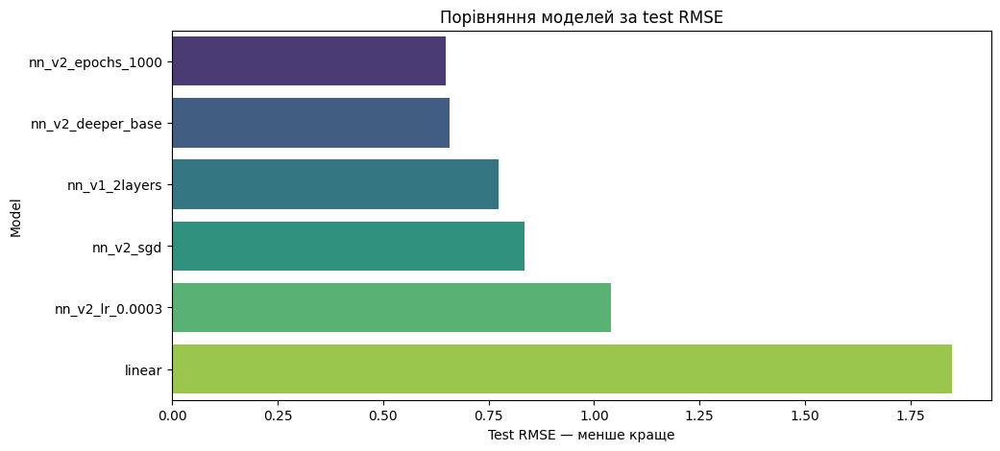

In [53]:
winner = final_results.iloc[0]

linear_row = final_results[
    final_results["model"] == "linear"
].iloc[0]

rmse_improvement_percent = (
    (linear_row["test_rmse"] - winner["test_rmse"])
    / linear_row["test_rmse"]
    * 100
)

print(f"Переможець: {winner['model']}")
print(f"Test RMSE переможця: {winner['test_rmse']:.4f}")
print(f"Test R² переможця: {winner['test_r2']:.4f}")
print(f"Зміна RMSE відносно linear: {rmse_improvement_percent:.2f}%")

## 4. Графік порівняння моделей

plt.figure(figsize=(11, 5))

sns.barplot(
    data=final_results,
    x="test_rmse",
    y="model",
    hue="model",
    legend=False,
    palette="viridis"
)

plt.title("Порівняння моделей за test RMSE")
plt.xlabel("Test RMSE — менше краще")
plt.ylabel("Model")
plt.show()

In [54]:
%tensorboard --logdir runs

Reusing TensorBoard on port 6006 (pid 2936), started 0:07:09 ago. (Use '!kill 2936' to kill it.)

<IPython.core.display.Javascript object>

Найкращою моделлю стала nn_v2_epochs_1000, обрана за найменшою
validation MSE — 0.4044 на 923-й епосі. На test-вибірці вона має
RMSE = ..., MAE = ... та R² = ....

Порівняно з linear baseline, RMSE змінився з ... до ..., тобто на ...%.
Отже, нейромережа [суттєво / незначно] покращила прогнозування якості вина.

Найбільший позитивний ефект дала зміна кількості епох із 500 до 1000:
validation MSE зменшилась із 0.4376 до 0.4044. Зменшення learning rate
до 0.0003 і заміна Adam на SGD не дали кращого результату.


TensorBoard показав, що лінійна модель збіжується повільніше та має значно вищі train і validation втрати. Додавання прихованих шарів суттєво покращило результат. Найкращу validation-криву має глибша мережа, навчена до 1000 епох; її мінімальна validation MSE становить 0.4044 на 923-й епосі. Відчутного розходження між train і validation loss не спостерігається, тому сильного перенавчання не виявлено.

---
## 3. Gradio-застосунок: порівняння всіх варіантів наживо

Побудуйте аппку для своїх моделей

In [55]:
%pip install -q gradio

import gradio as gr

In [56]:
models_for_app = {
    "linear": linear_model,
    "nn_v1_2layers": nn_v1_results["model"],
    "nn_v2_deeper_base": nn_v2_results["model"],
    "nn_v2_lr_0.0003": nn_v2_lr_0003_results["model"],
    "nn_v2_sgd": nn_v2_sgd_results["model"],
    "nn_v2_epochs_1000": nn_v2_epochs_1000_results["model"]
}

for model in models_for_app.values():
    model.eval()

In [57]:
feature_names = X_train.columns.tolist()

def compare_wine_models(*values):
    input_df = pd.DataFrame(
        [values],
        columns=feature_names
    )

    input_scaled = scaler.transform(input_df)

    input_tensor = torch.tensor(
        input_scaled,
        dtype=torch.float32
    )

    predictions = []

    for model_name, model in models_for_app.items():
        model.eval()

        with torch.no_grad():
            prediction = model(input_tensor).item()

        predictions.append({
            "model": model_name,
            "predicted_quality": round(prediction, 3)
        })

    predictions_df = (
        pd.DataFrame(predictions)
        .sort_values("predicted_quality", ascending=False)
        .reset_index(drop=True)
    )

    best_model_prediction = predictions_df.iloc[0]

    summary = (
        f"Найвище передбачення дала модель "
        f"**{best_model_prediction['model']}**: "
        f"**{best_model_prediction['predicted_quality']}**."
    )

    return predictions_df, summary

In [58]:
input_components = []

for feature in feature_names:
    input_components.append(
        gr.Number(
            label=feature,
            value=float(X_train[feature].median())
        )
    )

In [59]:
with gr.Blocks(title="Wine Quality: Model Comparison") as demo:
    gr.Markdown("""
    # Wine Quality: порівняння моделей

    Введіть фізико-хімічні характеристики вина.
    Застосунок покаже прогноз `quality` від кожного варіанта моделі.
    """)

    with gr.Row():
        with gr.Column():
            gr.Markdown("## Вхідні характеристики вина")

            for component in input_components:
                component.render()

            predict_button = gr.Button(
                "Порівняти моделі",
                variant="primary"
            )

        with gr.Column():
            gr.Markdown("## Прогнози моделей")

            predictions_output = gr.Dataframe(
                headers=["model", "predicted_quality"],
                label="Передбачення quality",
                interactive=False
            )

            summary_output = gr.Markdown()

    predict_button.click(
        fn=compare_wine_models,
        inputs=input_components,
        outputs=[predictions_output, summary_output]
    )

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2212eb0fec65a26dce.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [60]:
from pathlib import Path
import shutil

LAB2_DIR = Path("lab2")
MODELS_DIR = LAB2_DIR / "models"
RUNS_DIR = LAB2_DIR / "runs"

MODELS_DIR.mkdir(parents=True, exist_ok=True)

old_runs_dir = Path("runs")

if old_runs_dir.exists() and not RUNS_DIR.exists():
    shutil.move(str(old_runs_dir), str(RUNS_DIR))
else:
    RUNS_DIR.mkdir(parents=True, exist_ok=True)

print("Models:", MODELS_DIR)
print("TensorBoard logs:", RUNS_DIR)

Models: lab2/models
TensorBoard logs: lab2/runs


In [61]:
%tensorboard --logdir lab2/runs


<IPython.core.display.Javascript object>

In [62]:
models_to_save = {
    "linear.pt": linear_model,
    "nn_v1.pt": nn_v1_results["model"],
    "nn_v2.pt": nn_v2_results["model"],
    "nn_v2_lr_0.0003.pt": nn_v2_lr_0003_results["model"],
    "nn_v2_sgd.pt": nn_v2_sgd_results["model"],
    "nn_v2_epochs_1000.pt": nn_v2_epochs_1000_results["model"]
}

for filename, model in models_to_save.items():
    checkpoint = {
        "model_name": filename.replace(".pt", ""),
        "feature_names": feature_names,
        "state_dict": model.state_dict()
    }

    torch.save(
        checkpoint,
        MODELS_DIR / filename
    )

print("Збережені моделі:")

for model_path in MODELS_DIR.glob("*.pt"):
    print("-", model_path)

Збережені моделі:
- lab2/models/linear.pt
- lab2/models/nn_v2_lr_0.0003.pt
- lab2/models/nn_v2_epochs_1000.pt
- lab2/models/nn_v2_sgd.pt
- lab2/models/nn_v1.pt
- lab2/models/nn_v2.pt


In [63]:
results_to_save = final_results.rename(columns={
    "model": "Model",
    "test_mse": "MSE",
    "test_rmse": "RMSE",
    "test_mae": "MAE",
    "test_r2": "R2"
})

results_path = LAB2_DIR / "results.csv"

results_to_save.to_csv(
    results_path,
    index=False
)

display(results_to_save.round(4))
print(f"Таблицю збережено: {results_path}")

,Model,MSE,RMSE,MAE,R2
0,nn_v2_epochs_1000,0.4215,0.6492,0.4922,0.3526
1,nn_v2_deeper_base,0.4317,0.6570,0.5027,0.3369
2,nn_v1_2layers,0.5966,0.7724,0.6024,0.0836
3,nn_v2_sgd,0.6972,0.8350,0.6433,-0.0710
4,nn_v2_lr_0.0003,1.0791,1.0388,0.8092,-0.6575
5,linear,3.4174,1.8486,1.7446,-4.2491


Таблицю збережено: lab2/results.csv


In [64]:
import shutil

archive_path = shutil.make_archive(
    "lab2_submission",
    "zip",
    root_dir=".",
    base_dir="lab2"
)

print(archive_path)


/content/lab2_submission.zip


---
### Як здавати лабу

У форму (https://forms.gle/8Dbc9zB8L5tsNuNEA) здати посилання на **публічний** репозиторій, який містить:

1. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Файли всіх натренованих варіантів моделі** (2.2-2.4) — лінійна регресія + всі варіанти нейромережі, кожен окремим `.pt` файлом.
3. **Логи TensorBoard** — папка `runs/` з усіма прогонами, щоб можна було відкрити криві навчання, не перезапускаючи ноутбук.
4. **Таблицю результатів** — `results.csv` з порівнянням усіх варіантів (модель, MSE, RMSE, MAE, R² на test).
5. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab2/nn_task.ipynb
/lab2/models/linear.pt
/lab2/models/nn_v1.pt
/lab2/models/nn_v2.pt
/lab2/models/...        (усі інші варіанти з 2.3-2.4)
/lab2/runs/*
/lab2/results.csv
```